# Lab 03 — Multiclass Attack Classification

*AI Cybersecurity Masterclass · Lab 03 · AI60secLab*

**Companion video:** [▶ How AI Tells Cyber Attacks Apart](https://www.youtube.com/watch?v=KxNnMcXg2Tw&list=PLG4l6Ssi9A00)

## Research question
How well can a baseline model distinguish between attack categories?

The purpose is not merely to obtain one global score. We want to identify which attack classes the model understands well and which classes it confuses.

In [ ]:
# Setup: works in Google Colab and locally. No uploads needed.
# In Colab this clones the course repo, which already includes the UNSW-NB15 data.
from pathlib import Path
import sys, os

REPO_URL = "https://github.com/Jacquelinepersha/ai-cybersecurity-public-labs.git"
REPO_NAME = "ai-cybersecurity-public-labs"

try:
    import google.colab  # noqa: F401
    if not Path(REPO_NAME).exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir(REPO_NAME)
except ImportError:
    pass

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from src.data_loader import load_unsw
from src.preprocessing import split_xy, align_columns, build_preprocessor
from src.features import drop_identifier_like_columns
from src.evaluation import multiclass_report

train, test = load_unsw(DATA_DIR)

X_train, y_train = split_xy(train, "attack_cat")
X_test, y_test = split_xy(test, "attack_cat")
X_train, X_test = align_columns(X_train, X_test)

X_train = drop_identifier_like_columns(X_train)
X_test = drop_identifier_like_columns(X_test)

,training_examples
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


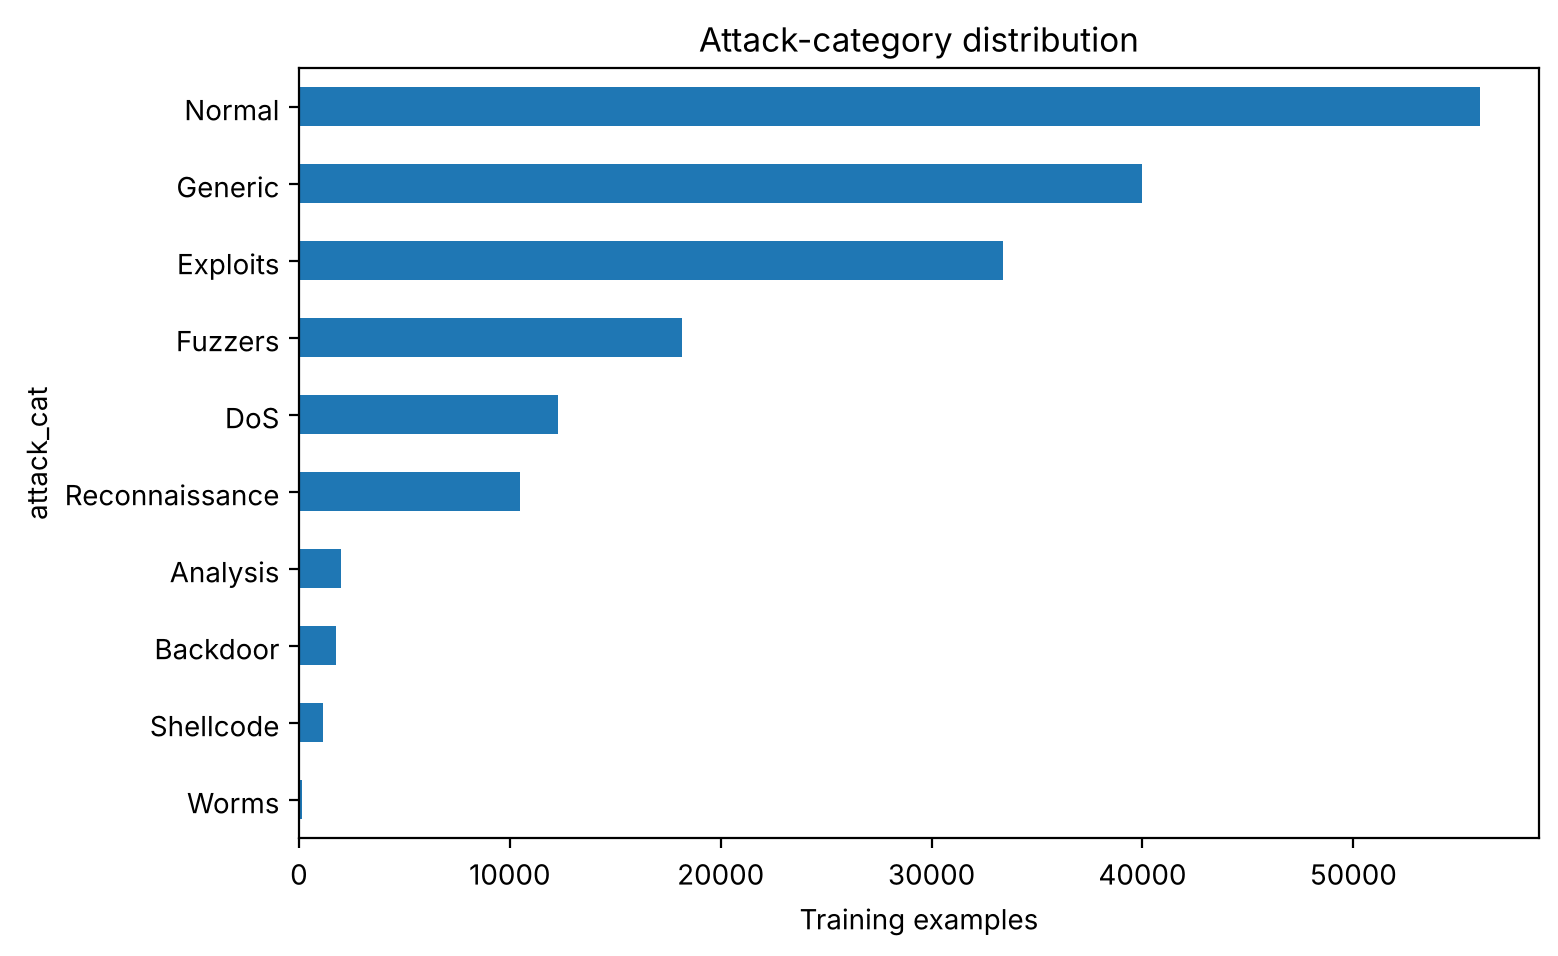

In [3]:
counts = y_train.value_counts()
display(counts.rename("training_examples").to_frame())

ax = counts.sort_values().plot(kind="barh", figsize=(8, 5))
ax.set_title("Attack-category distribution")
ax.set_xlabel("Training examples")
plt.show()

In [4]:
model = Pipeline([
    ("preprocess", build_preprocessor(X_train, scale_numeric=False)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1,
    )),
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

report = multiclass_report(y_test, predictions)
display(report.round(3))

,precision,recall,f1-score,support
Analysis,0.014,0.018,0.016,677.00
Backdoor,0.037,0.321,0.066,583.00
DoS,0.292,0.216,0.248,4089.00
Exploits,0.733,0.675,0.703,11132.00
Fuzzers,0.300,0.578,0.395,6062.00
Generic,0.999,0.967,0.983,18871.00
Normal,0.960,0.768,0.853,37000.00
Reconnaissance,0.931,0.795,0.858,3496.00
Shellcode,0.400,0.648,0.494,378.00
Worms,0.727,0.182,0.291,44.00


In [5]:
class_rows = report.drop(
    index=["accuracy", "macro avg", "weighted avg"],
    errors="ignore"
)

display(
    class_rows
    .sort_values("f1-score")
    [["precision", "recall", "f1-score", "support"]]
    .head(10)
    .round(3)
)

,precision,recall,f1-score,support
Analysis,0.014,0.018,0.016,677.0
Backdoor,0.037,0.321,0.066,583.0
DoS,0.292,0.216,0.248,4089.0
Worms,0.727,0.182,0.291,44.0
Fuzzers,0.300,0.578,0.395,6062.0
Shellcode,0.400,0.648,0.494,378.0
Exploits,0.733,0.675,0.703,11132.0
Normal,0.960,0.768,0.853,37000.0
Reconnaissance,0.931,0.795,0.858,3496.0
Generic,0.999,0.967,0.983,18871.0


## Your analysis

- Which attack categories are hardest to detect?
- Do rare classes have lower recall?
- Compare macro F1 and weighted F1.
- Why can a strong weighted score hide a security weakness?